# 01 - Exploratory analysis of credit card fraud

**Goal:** understand the data before modeling by answering questions such as:
1. Do fraudulent transactions have different amounts?
2. Is there a riskier time of day?
3. Which features best separate the classes?
4. Is the problem easy or hard?

**Key findings**
- Extreme imbalance: **0.167%** of transactions are fraud (473 / 283,726). Accuracy is useless; use PR-AUC, recall, precision and business cost.
- Fraud amounts are **bimodal**: many tiny "card-testing" amounts (median 9.8 vs 22 for normal) but a higher mean (124 vs 88). `99.99` alone has an 8% fraud rate.
- The fraud rate peaks **2-4 hours after the start of the recording** (relative time, not clock time), during the low-volume period, but the signal is noisy across the two days.
- **V14, V4, V12, V11, V10, V16** separate the classes best, and this ranking is stable on the training period alone.
- No single feature is enough: a one-feature rule cannot reach high recall without flooding analysts with false alerts. A multivariate model is needed.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from data_processing import load_data, remove_duplicate_rows, standardized_mean_difference

sns.set_theme(style="whitegrid")

## 0. Loading and cleaning
The features `V1`-`V28` are anonymised PCA components; only `Time` and `Amount` are raw. The only cleaning step is removing exact duplicates.

In [2]:
raw = load_data(PROJECT_ROOT / "data" / "creditcard.csv")
data = remove_duplicate_rows(raw)
data["Hour"] = (data["Time"] // 3600 % 24).astype(int)
data["Day"] = (data["Time"] // 86400).astype(int)

pd.Series({
    "rows (raw)": len(raw),
    "duplicates removed": len(raw) - len(data),
    "frauds among duplicates": int(raw["Class"].sum() - data["Class"].sum()),
    "missing values": int(data.isna().sum().sum()),
    "rows (clean)": len(data),
    "frauds": int(data["Class"].sum()),
    "fraud rate (%)": round(100 * data["Class"].mean(), 3),
}, dtype=object).to_frame("value")

,value
rows (raw),284807
duplicates removed,1081
frauds among duplicates,19
missing values,0
rows (clean),283726
frauds,473
fraud rate (%),0.167


## 1. Amount

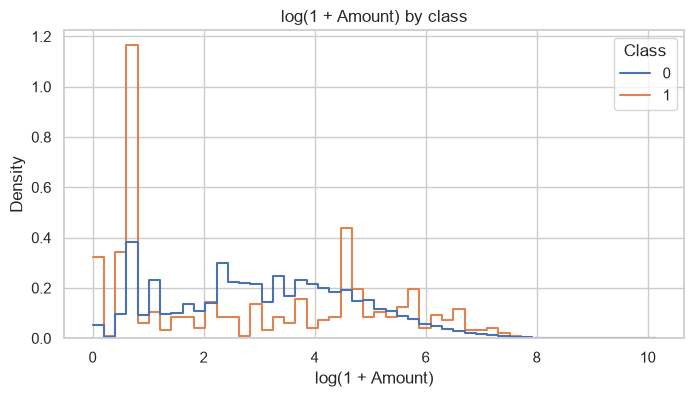

,mean,25%,50%,75%,max
Class,,,,,
0,88.41,5.67,22.00,77.46,25691.16
1,123.87,1.00,9.82,105.89,2125.87


,transactions,frauds,fraud_rate_%
Amount,,,
1.00,13566,105,0.77
99.99,330,27,8.18
0.00,1808,25,1.38
0.76,2977,17,0.57
0.77,1443,10,0.69
0.01,718,5,0.70


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data.assign(log_amount=np.log1p(data["Amount"])), x="log_amount", hue="Class",
             stat="density", common_norm=False, bins=50, element="step", fill=False, ax=ax)
ax.set(title="log(1 + Amount) by class", xlabel="log(1 + Amount)")
plt.show()

display(data.groupby("Class")["Amount"].describe()[["mean", "25%", "50%", "75%", "max"]].round(2))

by_amount = data.groupby("Amount")["Class"].agg(transactions="size", frauds="sum")
by_amount["fraud_rate_%"] = 100 * by_amount["frauds"] / by_amount["transactions"]
by_amount.sort_values("frauds", ascending=False).head(6).round(2)

**Takeaways**
- Half of the frauds are below 10 EUR (card testing: small charges to check that a stolen card works). Yet the fraud mean is *higher* than the normal mean because of a tail of large frauds (up to 2,126 EUR).
- Recurring amounts (`1.00`, `0.00`, `0.76`) concentrate many frauds but also many normal transactions, so their fraud rate stays below 1.5%. `99.99` is the exception: an 8% fraud rate, about 50x the average.
- Because missed large frauds cost more, the modeling uses `Amount` in the business cost, not only as a feature.

## 2. Time of day
`Time` is in seconds since the first transaction and covers two days, so `Hour` means **hours since the first transaction, modulo 24**: it is a relative value, not a clock time. The dataset does not say when the recording starts, so "hour 2" is not 2 a.m.

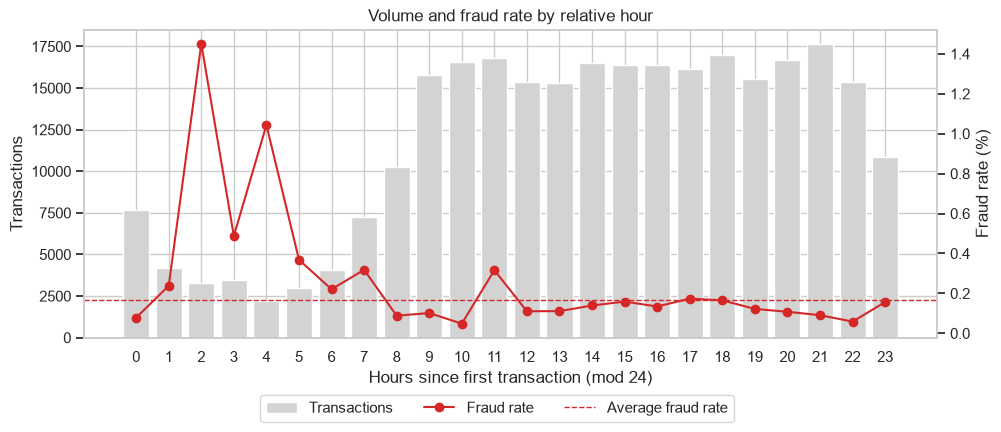

Day,0,1
Hour,,
1,0.09,0.40
2,1.34,1.56
3,0.72,0.24
4,0.55,1.52
5,0.66,0.00
11,0.51,0.12


In [4]:
hourly = data.groupby("Hour")["Class"].agg(transactions="size", fraud_rate="mean")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(hourly.index, hourly["transactions"], color="lightgray", label="Transactions")
ax.set(title="Volume and fraud rate by relative hour", xlabel="Hours since first transaction (mod 24)", ylabel="Transactions", xticks=range(24))
ax2 = ax.twinx()
ax2.plot(hourly.index, 100 * hourly["fraud_rate"], color="tab:red", marker="o", label="Fraud rate")
ax2.axhline(100 * data["Class"].mean(), color="tab:red", linestyle="--", linewidth=1, label="Average fraud rate")
ax2.set_ylabel("Fraud rate (%)")
ax2.grid(False)
fig.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12))
plt.show()

# Are the peaks repeated on both days?
data.pivot_table(index="Hour", columns="Day", values="Class", aggfunc="mean").mul(100).loc[[1, 2, 3, 4, 5, 11]].round(2)

**Takeaways**
- The fraud rate is highest at relative hours 2-4 (0.5-1.5%, up to ~9x the average), exactly when transaction volume is at its lowest.
- *Hypothesis, not a fact:* the low-volume block (relative hours 1-6) looks like a night, which would place the start of the recording around midnight. If true, fraud peaks at night, when there is little legitimate activity. This cannot be verified from the data.
- Hour 2 is high on both days, but hours 3-5 and 11 are not consistent from one day to the next. With only two days, hour of day is a weak, noisy signal: worth testing as a feature (cyclical encoding), not worth relying on.

## 3. Most discriminative features
A raw mean difference favours large-scale columns, so features are ranked by the **standardised mean difference** (SMD = difference of class means / pooled standard deviation). `Time`, `Hour` and `Day` are excluded because they are not transaction properties.

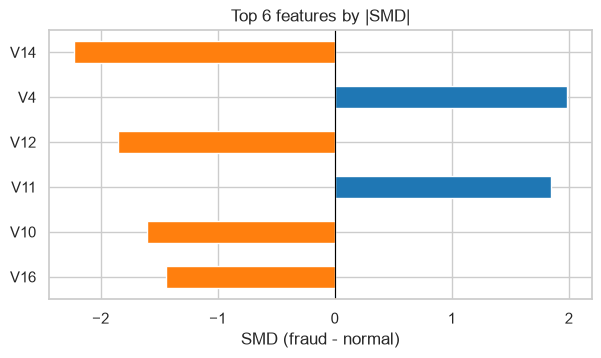

In [5]:
feature_columns = [c for c in data.columns if c.startswith("V")] + ["Amount"]
smd = standardized_mean_difference(data, feature_columns)
top = smd.head(6)

fig, ax = plt.subplots(figsize=(7, 3.5))
top.iloc[::-1].plot.barh(color=np.where(top.iloc[::-1] > 0, "tab:blue", "tab:orange"), ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Top 6 features by |SMD|", xlabel="SMD (fraud - normal)")
plt.show()

**Takeaways**
- `V14` (SMD -2.2), `V12`, `V10` and `V16` have much **lower** values for fraud; `V4` and `V11` much **higher**. These are very large effects (|SMD| > 1.4, where 0.8 is usually called "large").
- `Amount` is not in the top 6: its signal is in the shape of its distribution (bimodal), not in its mean.
- The PCA components are anonymised, so no domain interpretation is possible.

## 4. How separable are the classes?

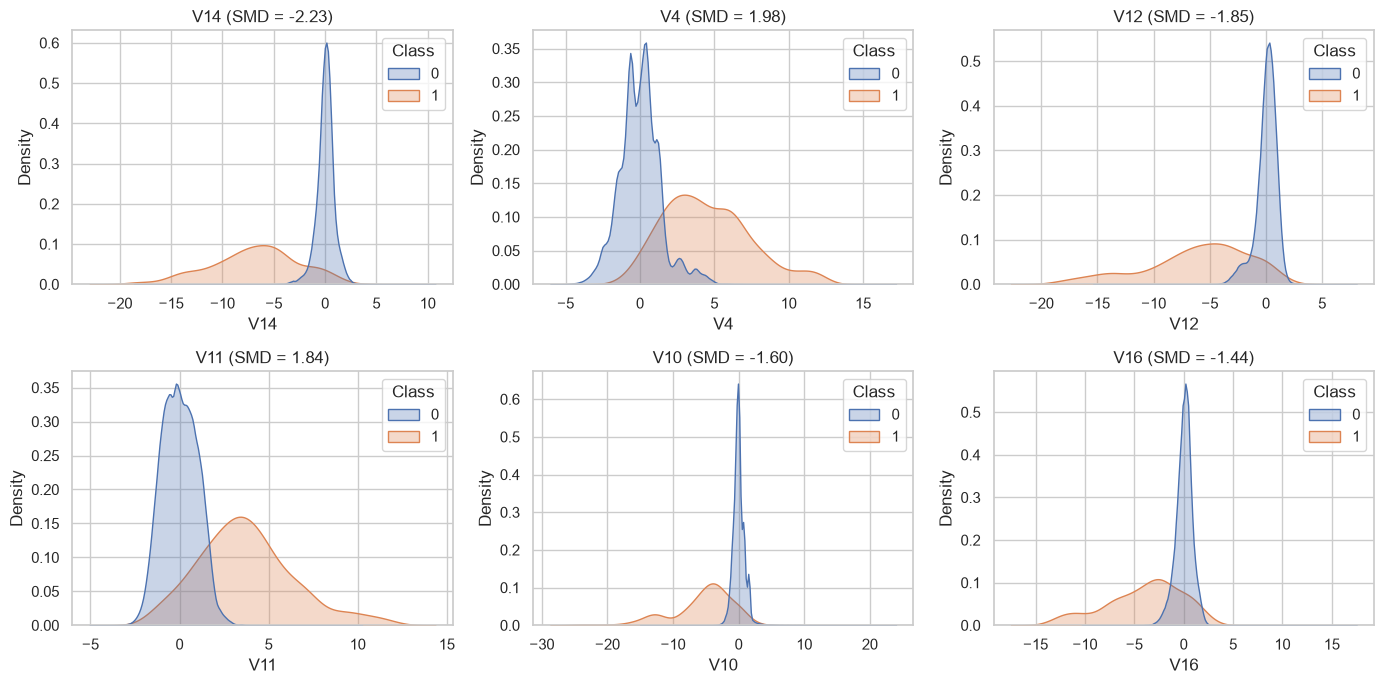

,recall_%,precision_%,false_alerts
rule,,,
V14 < -6,56.7,69.4,118
V14 < -5,65.1,61.5,193
V14 < -4,76.3,44.4,452
V14 < -3,81.6,16.5,1947
V14 < -2,85.0,5.8,6501


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for feature, ax in zip(top.index, axes.flat):
    sns.kdeplot(data, x=feature, hue="Class", common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.set_title(f"{feature} (SMD = {smd[feature]:.2f})")
plt.tight_layout()
plt.show()

# Best single-feature rule: flag transactions below a threshold on the top feature
best = top.index[0]
rows = []
for threshold in [-6, -5, -4, -3, -2]:
    flagged = data[best] < threshold
    caught = (flagged & (data["Class"] == 1)).sum()
    false_alerts = (flagged & (data["Class"] == 0)).sum()
    rows.append({"rule": f"{best} < {threshold}", "recall_%": 100 * caught / data["Class"].sum(),
                 "precision_%": 100 * caught / flagged.sum(), "false_alerts": false_alerts})
pd.DataFrame(rows).set_index("rule").round(1)

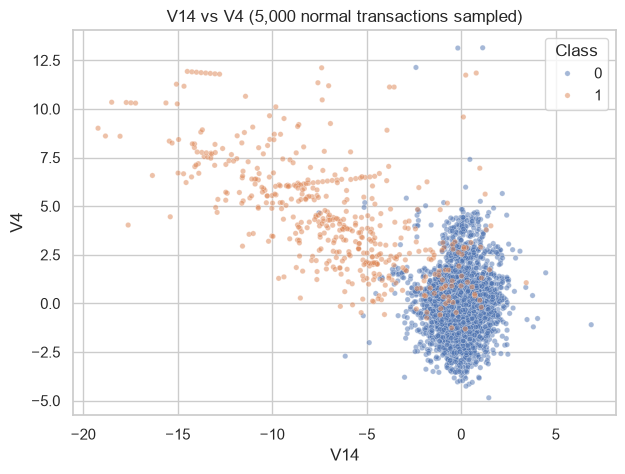

In [7]:
sample = pd.concat([data[data["Class"] == 0].sample(5000, random_state=42), data[data["Class"] == 1]])
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(sample, x="V14", y="V4", hue="Class", alpha=0.5, s=15, ax=ax)
ax.set_title("V14 vs V4 (5,000 normal transactions sampled)")
plt.show()

**Takeaways**
- Each top feature separates the bulk of the two classes, but the normal class has long tails that overlap the fraud region.
- With one feature, recall and precision trade off fast: `V14 < -5` catches 65% of frauds at 61% precision, while `V14 < -2` reaches 85% recall at the cost of **6,501 false alerts** (6% precision). Because fraud is so rare, even a tiny share of normal transactions in the tail outnumbers the frauds.
- Combining two features (scatter plot) already isolates frauds much better: the problem needs a **multivariate model**, and it looks learnable.

## 5. Is the feature ranking stable? (leakage check)
The charts above use the full dataset, which is fine for understanding the data. If they drive a modeling decision, that decision must hold on the training data alone. The cut below is the same chronological split as in the modeling notebook (first 70% of the timeline).

In [8]:
chronological = data.sort_values("Time", kind="stable")
train = chronological.iloc[: int(len(chronological) * 0.7)]
pd.DataFrame({
    "full data": smd.index[:8],
    "train (first 70%)": standardized_mean_difference(train, feature_columns).index[:8],
}, index=pd.RangeIndex(1, 9, name="rank"))

,full data,train (first 70%)
rank,,
1,V14,V14
2,V4,V4
3,V12,V12
4,V11,V11
5,V10,V10
6,V16,V16
7,V3,V17
8,V9,V3


**Takeaway:** the top 6 is identical on the training period alone (only ranks 7-8 differ), so the ranking is not an artefact of the later periods. No feature selection is needed anyway: all 28 components plus `Amount` are kept and the model decides.

## Conclusions for modeling
| Finding | Modeling decision |
|---|---|
| 0.167% fraud | Class / sample weights; evaluate with PR-AUC and business cost, never accuracy |
| Fraud amounts are bimodal, large frauds cost more | `log1p(Amount)` as a feature + `Amount` in the cost of a missed fraud |
| Fraud rate rises in the low-volume hours, but the signal is noisy and the hours are relative | Drop raw `Time`; optionally test a cyclical hour feature |
| No single feature separates the classes | Multivariate models (logistic regression baseline, tree ensembles, MLP) |
| Data covers two days, production scores the future | Chronological train / validation / test split |
| Precision collapses as recall rises | Choose the decision threshold on validation with an explicit cost (false alert vs missed fraud) |

Next: [02_pytorch_modeling_v2.ipynb](02_pytorch_modeling_v2.ipynb).